# Computer Vision Final Project: Automatic coin detection in images and calculation of the monetary amount

---

## 0) Introduction

### 0.1) Project Objectives
- Detection of euro coins in images by identifying circular edges
- Classify the detected coins based on their radii.
- Optionally train a neural network to classification performance.
- Calculate the total monetary value of all detected coins.



### 0.2) Basic Imports

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import cv2
import os
from pathlib import Path
from PIL import Image

---

### 0.3) Information for Downloading Pictures
Our self-token pictures can be downloaded here: https://bwsyncandshare.kit.edu/s/rgkxcTo9aeBaS2p

(There you can also find the pictures for training the Neural Network, which we will need later)

In [2]:
# load pictures from folder "data"
images = os.listdir("data/")

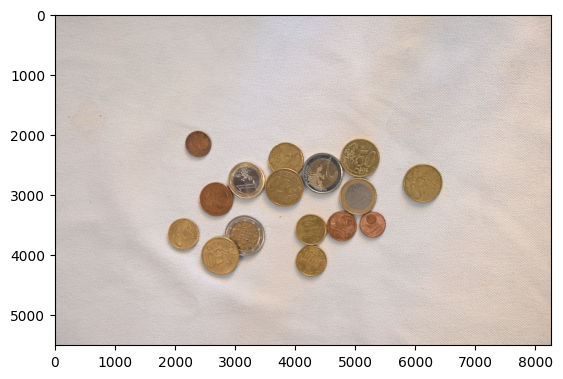

In [3]:
# plot a picture
image = mpimg.imread("data/DSC_1124.JPG")
plt.imshow(image)

Various coins can be detected in this image. Potential challenges of this task may be:

- the correct classification of different coin denominations
- the reliable detection and classification of coins even for overlapping coins
- distinguish between coins with only minimal differences in radius, such as the 50-cent coin and the 1-euro coin

---

# 1. Coin Detection

To find the correct parameters for the coin detection, we take the following three pictures. We chose them since there are the following differences:
- the distances between coins varry, ranging from well-sparated to closely positioned coins
- there are two pictures, in which some coins overlap
- coins may be placed upside down

### 1.1) Load data and plot

In [4]:
folder = Path("data")
img_coins = {
    "DSC_1119.JPG",
    "DSC_1124.JPG",
    "DSC_1125.JPG",
}

image_paths_coins = []

for data in folder.iterdir():
    if data.name in img_coins:
        image_paths_coins.append(data)
image_paths_coins.sort()


images_coins = []

for path in image_paths_coins:
    img = cv2.imread(str(path))
    if img is not None:
        images_coins.append((path.name, img))

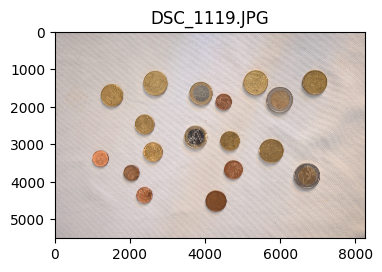

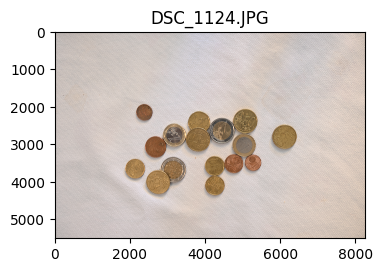

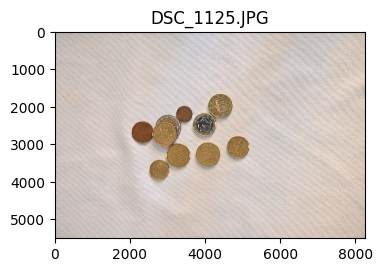

In [5]:
for name, img in images_coins:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(4, 3))
    plt.title(name)
    plt.imshow(img_rgb)
    plt.show()

In [6]:
np.shape(image)

(5504, 8256, 3)

Since the pictures have a shape of 5504*8256*3, we resize the images of 0.2 of their original dimension. This reduces the computational cost and enables faster processing of the images.

### 1.2) Resize images

In [7]:
def preprocess_resize(img, scale=0.2):
    resized = cv2.resize(img, None, fx=scale, fy=scale)
    return resized

### 1.3) Set radii for classfication and initialize counter
In this step, the coins are classified according to their radius, which we determined through testing.

In [8]:
def classify_coin(radius):
    if radius < 49:
        return "0.01"
    elif radius < 53:
        return "0.02"
    elif radius < 56:
        return "0.10"
    elif radius < 60:
        return "0.05"
    elif radius < 62:
        return "0.20"
    elif radius < 65:
        return "1.00"
    elif radius < 69:
        return "0.50"
    else:
        return "2.00"


coin_counter = {}
for name, img in images_coins:
    coin_counter[name] = {
        "0.01": 0,
        "0.02": 0,
        "0.05": 0,
        "0.10": 0,
        "0.20": 0,
        "0.50": 0,
        "1.00": 0,
        "2.00": 0
    }

### 1.4) Create hough pipeline

In [9]:
# Hough pipeline for coins
def hough_coins(img, counter, kernel_size, hough_dp, hough_min_dist, canny_threshold, hough_threshold, min_radius, max_radius):
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    output = rgb.copy()

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    blur_gray = cv2.GaussianBlur(gray, (kernel_size), 2)
    circles = cv2.HoughCircles(blur_gray, cv2.HOUGH_GRADIENT, dp=hough_dp, minDist=hough_min_dist, param1=canny_threshold, param2=hough_threshold, minRadius=min_radius, maxRadius=max_radius)
    
    
    if circles is not None:
        circles = np.round(circles[0, :]).astype("int")

        for (x, y, r) in circles:
            coin_type = classify_coin(r)
            if coin_type not in counter:
                counter[coin_type] = 0
            counter[coin_type] += 1
            
            cv2.circle(output, (x, y), r, (0, 255, 0), 4)
            cv2.putText(output, coin_type, (x-20, y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
            
    return output, counter

In [10]:
# define parameters
kernel_size = (9, 9)
hough_dp = 1.2
hough_min_dist = 40
canny_threshold = 100
hough_threshold = 35
min_radius = 40
max_radius = 120

### 1.5) Plot example picture

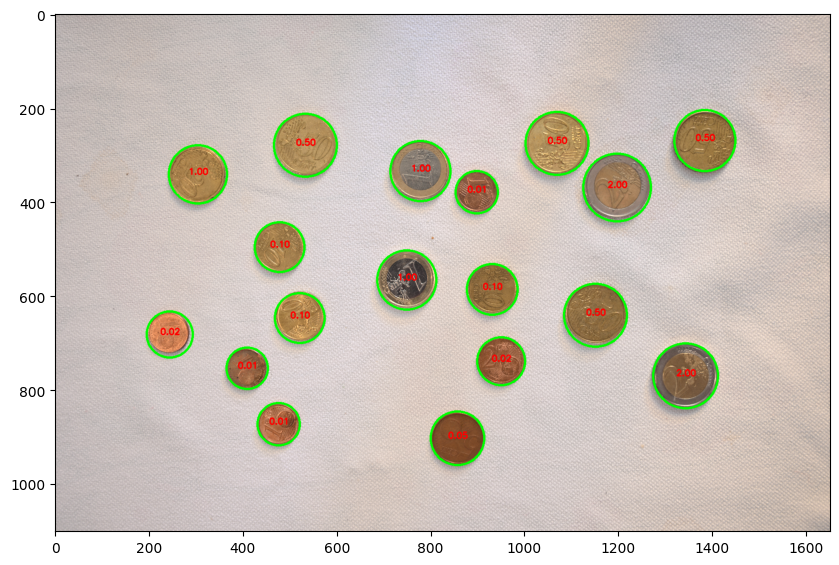

The following coins were detected: {'0.01': 3, '0.02': 2, '0.05': 1, '0.10': 3, '0.20': 0, '0.50': 4, '1.00': 3, '2.00': 2}


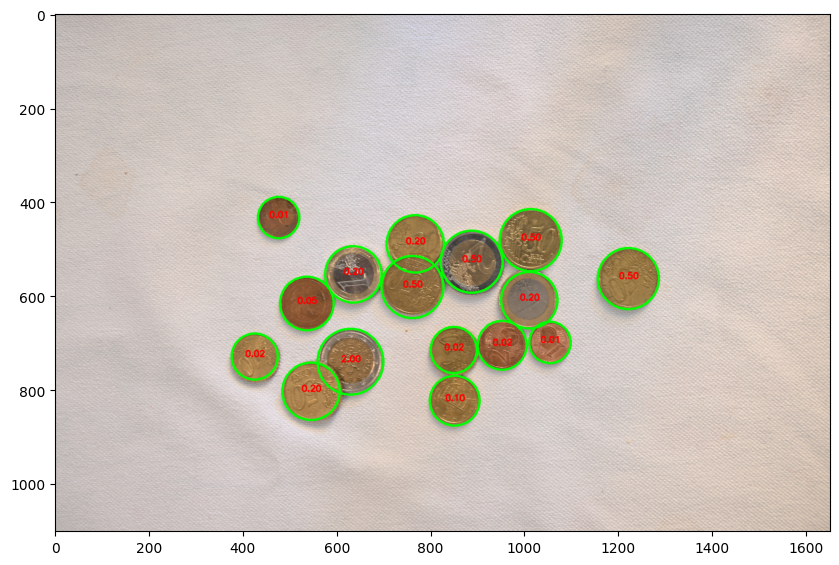

The following coins were detected: {'0.01': 2, '0.02': 3, '0.05': 1, '0.10': 1, '0.20': 4, '0.50': 4, '1.00': 0, '2.00': 1}


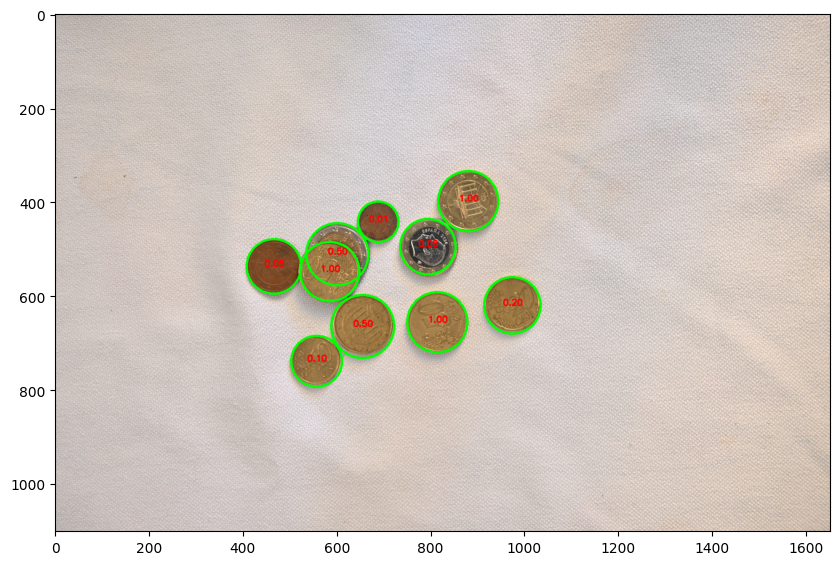

The following coins were detected: {'0.01': 1, '0.02': 0, '0.05': 2, '0.10': 1, '0.20': 1, '0.50': 2, '1.00': 3, '2.00': 0}


In [11]:
for name, img in images_coins:
    if img is None:
        continue

    img = preprocess_resize(img, scale=0.2)
    result, counter = hough_coins(img=img, counter=coin_counter[name], kernel_size=kernel_size, hough_dp=hough_dp, hough_min_dist=hough_min_dist, canny_threshold=canny_threshold, hough_threshold=hough_threshold, min_radius=min_radius, max_radius=max_radius)

    plt.figure(figsize=(10, 8))
    plt.imshow(result)
    plt.show()
    print(f"The following coins were detected: {counter}")

Unfortunately, the coin detection works only to a limited extent. As expected, distinguishing between the 50-cent and 1-euro coins is challenging, since their radius is almost the same. In addition, shadows can lead to increased radii, which can be seen in the first image on the far left at the 2-cent coin. Although it is correctly detected, the contour is overestimated due to the shadow.

To improve performance, we considered classifying the coins into copper and gold/silver groups. However, since the detection of copper coins is already nearly perfect, there wouldn't be a significant improvement.

Therefore, we decided to incorporate artificial intelligence into our project.

---

## 2) Coin Detection with AI

For the second part of the project, we will:

- download a dataset from Kaggle. The major difference is that each image in this dataset contains only a single coin, whereas our own images contain multiple coins. (Kaggle: Euro Coin TensorFlow Dataset, https://www.kaggle.com/datasets/sh1nd3l/euro-coin-tensorflow-dataset/data, last accessed on 09 June 2026; **we also uploaded it on BWSYNC&SHARE:** https://bwsyncandshare.kit.edu/s/rgkxcTo9aeBaS2p).
- apply Transfer Learning and train the model
- crop the given images into multiple smaller images such that each cropped image contains only a single coin, and store these images in a folder
- apply the trained model to the images in this folder to classify the coins
- calculate the total monetary value of all classified coins


### 2.1) Train Model
#### 2.1.1) Data Augmentation and load data

In [12]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

dataset_dir = "data/coin_tf_dataset"

# parameter
img_size = (128, 128)
batch_size = 32
train_ratio = 0.8

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

# idata augmentation
train_tf = transforms.Compose([
    transforms.Resize(img_size),
    transforms.RandomRotation(360),
    transforms.RandomPerspective(distortion_scale=0.1),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_tf = transforms.Compose([
    transforms.Resize(img_size),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


# load data and split
full_dataset = datasets.ImageFolder(dataset_dir)
indices = torch.randperm(len(full_dataset), generator=torch.Generator().manual_seed(42))

train_size = int(train_ratio * len(indices))

train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = torch.utils.data.Subset(datasets.ImageFolder(dataset_dir, transform=train_tf), train_indices)
val_dataset = torch.utils.data.Subset(datasets.ImageFolder(dataset_dir, transform=eval_tf), val_indices)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

class_names = full_dataset.classes

# print
print("Klassen: ", class_names)
print("Train size: ", len(train_dataset))
print("Val size: ", len(val_dataset))

Klassen:  ['0', '1', '2', '3', '4', '5', '6', '7']
Train size:  268
Val size:  68


Unfortunately, we only have a little dataset, which means that our model is unlikely to achieve an almost perfekt perfomance.

#### 2.1.2) Transfer Learning with ResNet18

In [13]:
from torchvision.models import resnet18
import torch.nn as nn

num_classes = len(class_names)
model = resnet18(weights="DEFAULT")
model.fc = nn.Linear(model.fc.in_features, num_classes)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [14]:
# define loss und optimizer
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.00005)

### 2.1.3) Training

In [15]:
# train loop
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

epochs = 20

for epoch in range(epochs):
    model.train()

    running_loss = 0.0
    correct = 0.0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = 100 * correct / total
    train_loss = running_loss / len(train_loader)

    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = 100 * val_correct / val_total

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Loss: {train_loss:.4f} "
          f"Train Acc: {train_acc:.2f}% "
          f"Val Acc: {val_acc:.2f}%")

c:\Users\Julia\PythonProjects2\.venv\Lib\site-packages\torch\cuda\__init__.py:187: UserWarning: cudaGetDeviceCount() returned cudaErrorNotSupported, likely using older driver or on CPU machine (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10\cuda\CUDAFunctions.cpp:88.)
  return torch._C._cuda_getDeviceCount() > 0


Epoch [1/20] Loss: 1.8840 Train Acc: 27.99% Val Acc: 27.94%
Epoch [2/20] Loss: 1.2119 Train Acc: 65.67% Val Acc: 50.00%
Epoch [3/20] Loss: 0.8470 Train Acc: 73.88% Val Acc: 55.88%
Epoch [4/20] Loss: 0.6547 Train Acc: 82.09% Val Acc: 57.35%
Epoch [5/20] Loss: 0.4588 Train Acc: 89.18% Val Acc: 66.18%
Epoch [6/20] Loss: 0.3851 Train Acc: 91.04% Val Acc: 76.47%
Epoch [7/20] Loss: 0.2948 Train Acc: 92.16% Val Acc: 79.41%
Epoch [8/20] Loss: 0.2836 Train Acc: 94.78% Val Acc: 79.41%
Epoch [9/20] Loss: 0.1815 Train Acc: 96.27% Val Acc: 86.76%
Epoch [10/20] Loss: 0.1892 Train Acc: 95.90% Val Acc: 91.18%
Epoch [11/20] Loss: 0.2057 Train Acc: 95.15% Val Acc: 88.24%
Epoch [12/20] Loss: 0.1062 Train Acc: 98.51% Val Acc: 94.12%
Epoch [13/20] Loss: 0.1211 Train Acc: 97.39% Val Acc: 92.65%
Epoch [14/20] Loss: 0.0843 Train Acc: 99.25% Val Acc: 92.65%
Epoch [15/20] Loss: 0.0673 Train Acc: 99.25% Val Acc: 94.12%
Epoch [16/20] Loss: 0.0669 Train Acc: 99.25% Val Acc: 92.65%
Epoch [17/20] Loss: 0.0527 Train 

### 2.2) Circle detection with hough and crop pictures
#### 2.2.1) Preprocess images

In [16]:
# BGR -> GRAY
def preprocess(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (9, 9), 2)
    return gray

def resize_image(image, target_width=1200):
    if image.shape[1] <= target_width:
        return image

    scale = target_width / image.shape[1]

    return cv2.resize(
        image,
        None,
        fx=scale,
        fy=scale
    )

#### 2.2.2) Hough Pipeline

In [17]:
# Hough
def detect_circles(gray):
    circles = cv2.HoughCircles(
        gray,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=40,
        param1=100,
        param2=35,
        minRadius=40,
        maxRadius=120
    )

    if circles is None:
        return None

    return np.round(circles[0]).astype(int)

#### 2.2.3) Crop Coins

In [18]:
def crop_coin(image, x, y, r, padding=10):

    h, w = image.shape[:2]
    x1 = max(0, x - r - padding)
    y1 = max(0, y - r - padding)
    x2 = min(w, x + r + padding)
    y2 = min(h, y + r + padding)
    crop = image[y1:y2, x1:x2].copy()

    # generate mask around circles
    mask = np.zeros(crop.shape[:2], dtype=np.uint8)
    cx = x - x1
    cy = y - y1
    cv2.circle(mask, (cx, cy), r, 255, -1)
    white_bg = np.full_like(crop, 255)
    crop = np.where(
        mask[:, :, np.newaxis] == 255,
        crop,
        white_bg
    )

    crop = cv2.resize(crop, (128, 128))

    return crop

def draw_detections(image, circles):
    img_circles = image.copy()
    for x, y, r in circles:
        cv2.circle(img_circles, (x, y), r, (0, 255, 0), 2)
        cv2.circle(img_circles, (x, y), 3, (0, 0, 255), -1)

    return img_circles

#### 2.2.4) Combine circle detection and crop

In [19]:
def detect_and_crop(image_path, output_dir=None, plot=True):

    image = cv2.imread(image_path)
    image = preprocess_resize(image)
    gray = preprocess(image)
    circles = detect_circles(gray)

    if circles is None:
        print("No coins detected")
        return []

    print(f"{len(circles)} coins detected.")

    crops = []

    if output_dir is not None:
        Path(output_dir).mkdir(exist_ok=True)

    for i, (x, y, r) in enumerate(circles):

        crop = crop_coin(image, x, y, r)
        crops.append(crop)

        if output_dir is not None:
            cv2.imwrite(os.path.join(output_dir, f"coin_{i:03d}.jpg"), crop)

    if plot:

        img_circles = draw_detections(image, circles)
        plt.figure(figsize=(12, 12))
        plt.imshow(cv2.cvtColor(img_circles, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.show()

    return crops, len(circles)

#### 2.2.5) Show an example

18 coins detected.


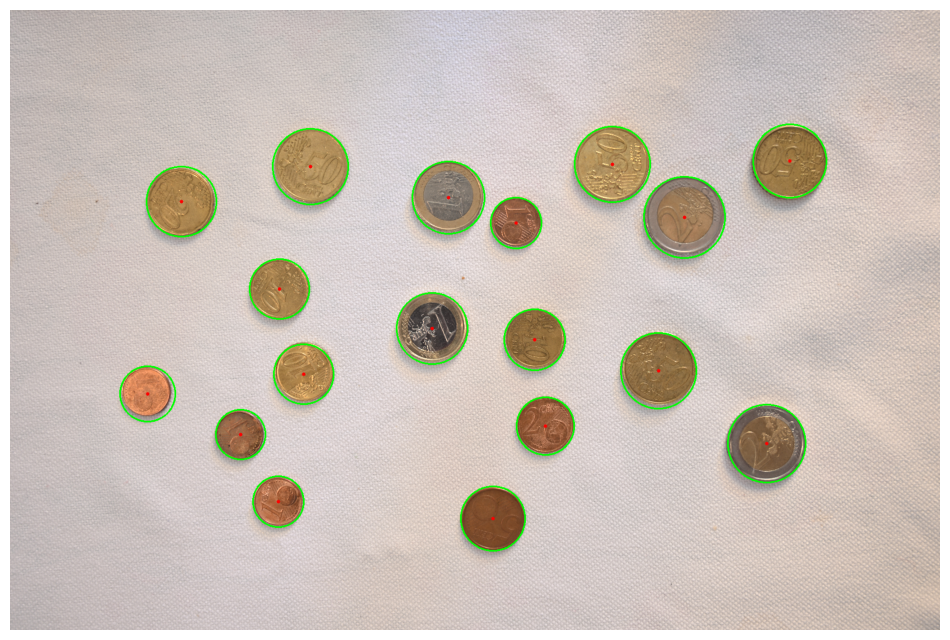

In [20]:
crops, _ = detect_and_crop("data/DSC_1119.JPG", output_dir="out_1119", plot=True)

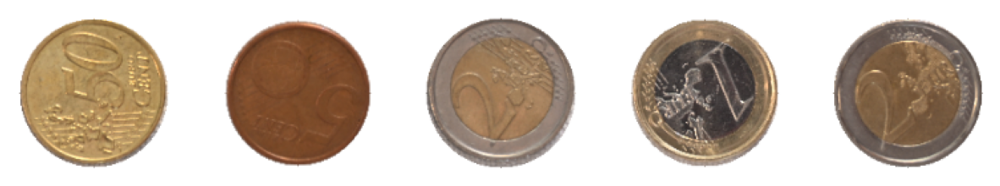

In [21]:
# plot little pictures of cropped image above
fig, axes = plt.subplots(1, 5, figsize=(15, 5))

for ax, crop in zip(axes, crops):
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax.axis("off")

plt.show()

### 2.3) Apply model on each picture of single coins

In [22]:
# load pictures from folder
from collections import Counter
def load_coin_images(folder_path):
    coins = []

    for file in sorted(os.listdir(folder_path)):
        if file.lower().endswith((".png", ".jpg", ".jpeg")):

            img = cv2.imread(os.path.join(folder_path, file))

            if img is not None:
                coins.append(img)

    return coins


# prepare coin for classfication
def prepare_coin(img):
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = Image.fromarray(img)
    return transform(img).unsqueeze(0)

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])


# classify coins
def predict_coins(coins, model, class_names, device):
    model.eval()
    total = 0.0
    counts = Counter()

    # mapping since the model has trained with classes 0 to 7
    mapping = {
        "0": 0.01,
        "1": 0.02,
        "2": 0.05,
        "3": 0.10,
        "4": 0.20,
        "5": 0.50,
        "6": 1.00,
        "7": 2.00
    }

    with torch.no_grad():
        for coin in coins:

            x = prepare_coin(coin).to(device)

            outputs = model(x)
            pred = torch.argmax(outputs, dim=1).item()

            label = class_names[pred]
            value = mapping[label]

            total += value
            counts[label] += 1

    coin_counter = {}

    for label, count in sorted(counts.items(), key=lambda item: mapping[item[0]]):
        value = mapping[label]
        coin_counter.update({value: count})

    return round(total, 2), coin_counter

In [23]:
# move model to cpu if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

### 2.4) Test with example

In [24]:
# predict coins
coins = load_coin_images("out_1119")

result, coin_counter = predict_coins(coins, model, train_dataset.dataset.classes, device)
print(result)

8.2


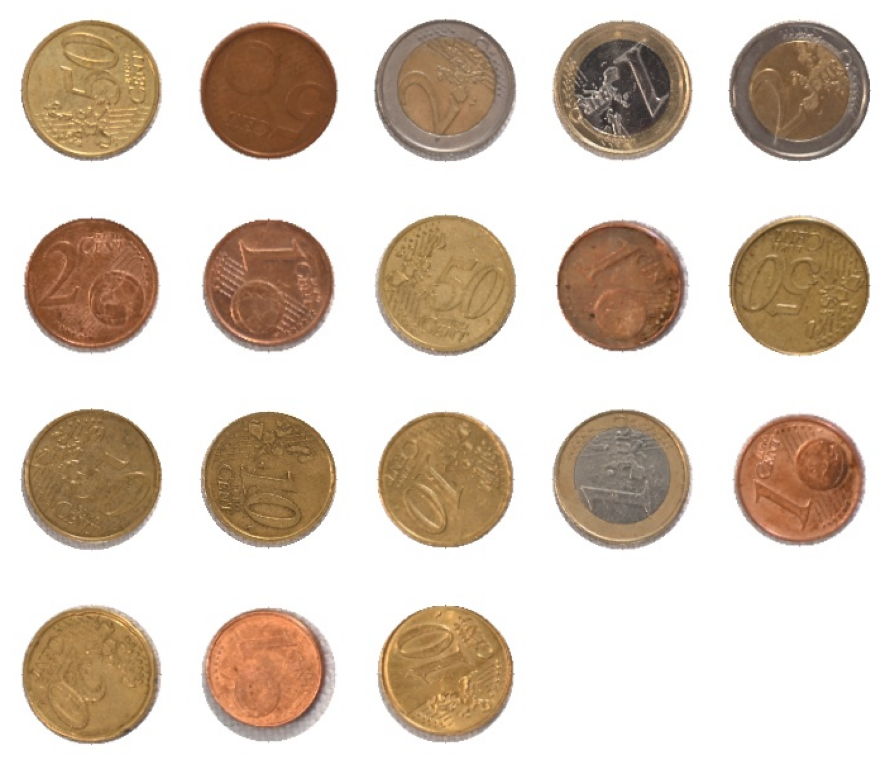

In [25]:
# plot each coin to check
folder = Path("out_1119")
image_paths = sorted([p for p in folder.iterdir()])
cols = 5
rows = (len(image_paths) + cols - 1) // cols
plt.figure(figsize=(9, 2*rows))

for i, img_path in enumerate(image_paths):
    img = Image.open(img_path)

    plt.subplot(rows, cols, i+1)
    plt.imshow(img)
    plt.axis("off")
plt.tight_layout()
plt.show() 

In [26]:
coin_counter

{0.01: 2, 0.02: 4, 0.1: 6, 0.5: 1, 1.0: 3, 2.0: 2}

| Euro-coin | in reality | detected |
|:---:|:---:|:---:|
| 0.01€ | 4 | 2 |
| 0.02€ | 1 | 5 |
| 0.05€ | 1 | 0 |
| 0.10€ | 3 | 2 |
| 0.20€ | 1 | 1 |
| 0.50€ | 4 | 4 |
| 1.00€ | 2 | 2 |
| 2.00€ | 2 | 2 |
| **Total** | *8.61€* | *8.52€* |

Observations:

- The 1-cent and 2-cent coins are very similar. Even for humans, the second coin in the last row is difficult to identify correctly.
- The model also struggles to distinguish between 10-cent, 20-cent, and 50-cent coins.
- In contrast, the model recognizes 1-euro and 2-euro coins almost perfectly.

---

Since the classfication through radii (in 1)) works almost perfect for little coins and the classfication through the ResNet-Model works almost perfect for larger coins, we decided to combine these two methods. 1-Cent-coin to 20-Cent-coin will be classified by their radii while 50-Cent-, 1€- and 2€-coins will be classified by the resnet model.

---

## 3) Combination of Classification through Radii and through ResNet-Model

### 3.1) create pipeline

In [27]:
def kombi(path, output_dir):
    img = cv2.imread(str(path))
    img = preprocess_resize(img, scale=0.2)

    coin_counter = {}
    coin_counter = {
        "0.01": 0,
        "0.02": 0,
        "0.05": 0,
        "0.10": 0,
        "0.20": 0,
        "0.50": 0,
        "1.00": 0,
        "2.00": 0
    }

    # 1) Classification through radii
    result_hough, counter_hough = hough_coins(img=img, counter=coin_counter, kernel_size=kernel_size, hough_dp=hough_dp, hough_min_dist=hough_min_dist, canny_threshold=canny_threshold, hough_threshold=hough_threshold, min_radius=min_radius, max_radius=max_radius)

    # 2) Classification through ResNet
    crops, real_amount_of_coins = detect_and_crop(path, output_dir=output_dir, plot=True)
    coins = load_coin_images(output_dir)

    result_resnet, counter_resnet = predict_coins(coins, model, train_dataset.dataset.classes, device)

    keys = list(coin_counter.keys())

    # 3) Combination: Overwrite coin counter of 1) by coin counter of 2) for the values 0.50, 1.00 and 2.00
    counter_total = counter_hough.copy()
    counter_total['0.50'] = counter_resnet[0.50]
    counter_total['1.00'] = counter_resnet[1.00]
    counter_total['2.00'] = counter_resnet[2.00]

    total = sum(counter_total.values())
    result = sum(float(key) * value for key, value in counter_total.items())
    return real_amount_of_coins, counter_total, total, result


### 3.2) Test Picture

18 coins detected.


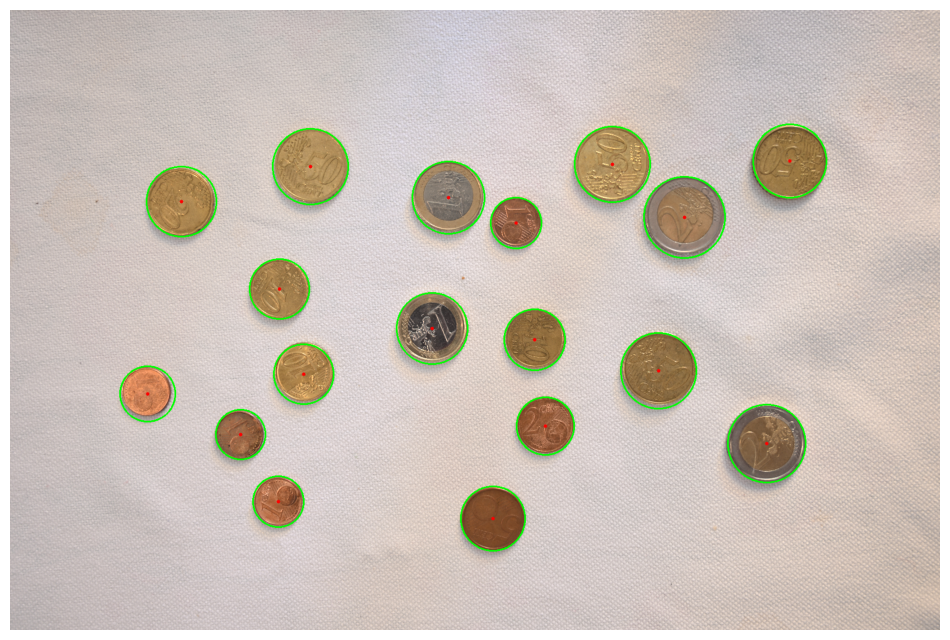

In [28]:
real_amount_of_coins, counter, total, result = kombi("data/DSC_1119.JPG", "out_1119")

In [29]:
print(f"The real amount of coins is {real_amount_of_coins}.")

The real amount of coins is 18.


In [30]:
print(f"However, due to the combination of the two methods, only {total} are classified.")

However, due to the combination of the two methods, only 15 are classified.


In [31]:
counter, result

({'0.01': 3,
  '0.02': 2,
  '0.05': 1,
  '0.10': 3,
  '0.20': 0,
  '0.50': 1,
  '1.00': 3,
  '2.00': 2},
 7.92)

The actual result is 8.61€.

| Euro-coin | in reality | detected |
|:---:|:---:|:---:|
| 0.01€ | 4 | 3 |
| 0.02€ | 1 | 2 |
| 0.05€ | 1 | 1 |
| 0.10€ | 3 | 3 |
| 0.20€ | 1 | 0 |
| 0.50€ | 4 | 4 |
| 1.00€ | 2 | 2 |
| 2.00€ | 2 | 2 |
| **Total** | *8.61€* | *8.42€* |

### 3.3) Another test picture

18 coins detected.


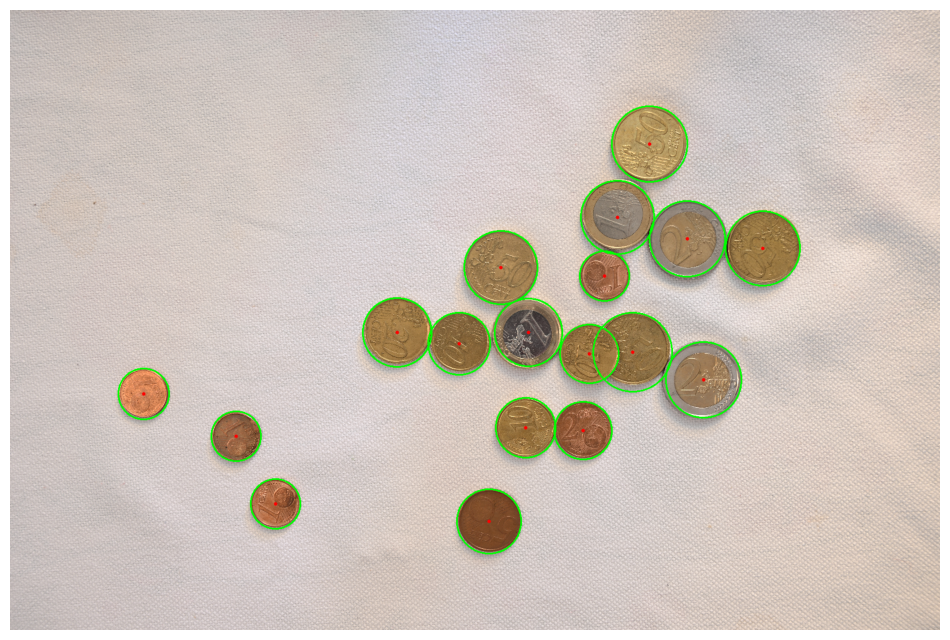

In [32]:
real_amount_of_coins, counter, total, result = kombi("data/DSC_1122.JPG", "out_1122")

In [33]:
counter, result

({'0.01': 4,
  '0.02': 2,
  '0.05': 1,
  '0.10': 2,
  '0.20': 2,
  '0.50': 3,
  '1.00': 2,
  '2.00': 2},
 8.23)

| Euro-coin | in reality | detected |
|:---:|:---:|:---:|
| 0.01€ | 4 | 4 |
| 0.02€ | 1 | 2 |
| 0.05€ | 1 | 1 |
| 0.10€ | 3 | 2 |
| 0.20€ | 1 | 2 |
| 0.50€ | 4 | 3 |
| 1.00€ | 2 | 2 |
| 2.00€ | 2 | 2 |
| **Total** | *8.61€* | *8.23€* |

## Quantitative Evaluation

The proposed system was evaluated using multiple test images containing different Euro coin denominations.

The radius-based approach provided fast predictions but was sensitive to variations in image scale and detection quality.

The ResNet18 classifier achieved more reliable classification results and demonstrated better generalization on unseen images.

The hybrid approach, which combines circle detection and deep learning classification,
 produced the most robust and consistent
  results across different test scenarios.

---

## 4) Conclusion

Overall, we would say that our coin detecting and classifying method is working well.

Unfortunately, there were many challenges we had to face:
- finding the right radii for each coin
- distinguishing between the 50-Cent and 1€-coin
- combining the two methods


To improve our project, we suggest training the ResNet model with a larger dataset. Furthermore, we would add coins placed upside down to our training set. Instead of combining both methods, it would be preferable to only take the trained model for classifying the coins. This would also have the advantage of enabling the detection and classification of coins in any image, rather than being limited to a specific input image size or a fixed distance between camera and object.
